### Purpose of this notebook

This notebook conducts the primary **causal analysis** to determine if channels classified as **Outperformers** (due to high engagement efficiency) are systematically different from comparable **Control** channels regarding their long-term **Growth Volatility**. 

It implements **Propensity Score Matching (PSM)**, utilizing covariates such as log-transformed subscriber count, channel age, and video count, to construct a **balanced sample** and thereby reduce the effects of **selection bias**. 

After validating the covariate balance, the notebook performs a final statistical test—the **Mann-Whitney U test**—to compare the **Coefficient of Variation (CV)** for weekly views and subscriber growth between the matched treated and control groups, definitively testing the hypothesis that Outperformers exhibit higher growth volatility.

In [1]:
import sys
import os
# This finds the directory *above* 'tests', which is your project root.
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))

if project_root not in sys.path:
    sys.path.insert(0, project_root)

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import mannwhitneyu

# Import the necessary helper functions and path constants
from src.data.dataloader import load_all_datasets
from src.data.preprocessing import complete_data_preprocessing, channels_preprocessing
from src.models.log_log_efficiency_model import linear_log_log_model

# Causal inference imports
import statsmodels.api as sm
from statsmodels.formula.api import logit
import networkx as nx

### 1. Configuration and Targeted Data Loading

In [3]:
# ----------------------------------------------------------------------
# Analysis Parameters
# ----------------------------------------------------------------------

SUBSET_SIZE = 5_000_000 # 5M rowsfor a robust sample

ZSCORE_THRESHOLD = 1.5  # Z-score for defining an 'Outperformer'

OBSERVATION_WEEKS = 52 # 1-year window
MIN_WEEKS_REQUIRED = 26 # 6-month minimum data

# PSM Covariates (Channel features to match on) - We log-transform skewed variables
COVARIATES = [
    'log_subscribers_cc', 
    'log_channel_age_days', 
    'log_videos_cc'
]
EXACT_MATCH_COVARIATE = 'category_cc' # Exact match on channel category

# Statistical Test
THRESHOLD_ALPHA = 0.05

MINIMUM_SAMPLES = 20  # Minimum samples required per group for statistical testing
MATCHING_CALIPER_VALUE = 0.0005

In [4]:
# ----------------------------------------------------------------------
# Define all necessary utility functions
# ----------------------------------------------------------------------

def calculate_cv(data_series):
    """Calculates the Coefficient of Variation (CV = Std Dev / Mean)."""
    mean = data_series.mean()
    std = data_series.std()
    return np.nan if mean == 0 else std / mean

def calculate_channel_cvs(group):
    analysis_window = group.tail(OBSERVATION_WEEKS)
    
    if len(analysis_window) < MIN_WEEKS_REQUIRED:
        return pd.Series([np.nan, np.nan], index=['cv_views', 'cv_subs'])

    cv_views = calculate_cv(analysis_window['delta_views'])
    cv_subs = calculate_cv(analysis_window['delta_subs'])
    
    return pd.Series([cv_views, cv_subs], index=['cv_views', 'cv_subs'])

def get_similarity(prop_score_1, prop_score_2):
    """Calculates similarity as the inverse of the absolute difference in prop scores."""
    epsilon = 1e-8 # Avoid division by zero
    return 1.0 / (abs(prop_score_1 - prop_score_2) + epsilon)

def match_by_max_weight(treated_df, control_df, exact_match_col='category', caliper=None):
    """
    Performs Maximum Weight Bipartite Matching using NetworkX.
    Matches Treated (is_outperformer=1) with Control (is_outperformer=0).
    """
    print(f"Building matching graph (Treated N={len(treated_df)}, Control N={len(control_df)})...")
    G = nx.Graph()

    # Iterate through all possible pairs
    for control_id, control_row in control_df.iterrows():
        for treated_id, treated_row in treated_df.iterrows():
            
            # 1. Enforce Exact Matching on the critical categorical covariate
            if control_row[exact_match_col] == treated_row[exact_match_col]:
            
                prop_score_control = control_row['Propensity_score']
                prop_score_treated = treated_row['Propensity_score']

                if caliper is not None and abs(prop_score_control - prop_score_treated) > caliper:
                    continue # Skip this match, the Propensity Score difference is too large

                # 2. Compute similarity based on Propensity Score
                similarity = get_similarity(prop_score_control, prop_score_treated)

                # 3. Add weighted edge (weight = similarity)
                G.add_weighted_edges_from([(control_id, treated_id, similarity)])

    print("Graph built. Finding maximum weight matching...")
    # 4. Generate the Maximum Weight Matching
    matching = nx.max_weight_matching(G)
    
    # Extract the IDs of the matched channels
    matched_ids = set()
    for u, v in matching:
        if u in treated_df.index and v in control_df.index:
            matched_ids.add(u)
            matched_ids.add(v)
        elif v in treated_df.index and u in control_df.index:
            matched_ids.add(u)
            matched_ids.add(v)
            
    # Return the matched channels
    return matched_ids

def calculate_smd(df, treat_col, covariate):
    """Calculates the Standardized Mean Difference (SMD) for a covariate."""
    treated = df[df[treat_col] == 1][covariate]
    control = df[df[treat_col] == 0][covariate]
    
    mean_diff = treated.mean() - control.mean()
    std_pool = np.sqrt((treated.var() + control.var()) / 2)
    
    return mean_diff / std_pool if std_pool > 0 else 0

### 2. Load and Preprocess Data

In [5]:
# ----------------------------------------------------------------------
# This cell loads all data and applies the full pipeline
# ----------------------------------------------------------------------

print(f"Loading ALL datasets with subset_size={SUBSET_SIZE}...")

channels_df, videos_df, timeseries_df, num_comments_df = load_all_datasets(
    subset_size=SUBSET_SIZE, 
    compressed_videos=False
)
print("Raw data loading complete.")

print("\nApplying preprocessing and merging (channels and timeseries)...")
videos_metadata_df, timeseries_df_processed = complete_data_preprocessing(
    channels_df=channels_df, 
    videos_metadata_df=videos_df, 
    timeseries_df=timeseries_df, 
    videos_num_comments_df=num_comments_df
)

# FIX: Process the channels_df to ensure all features (like channel_age_days) are created
channels_df = channels_preprocessing(channels_df)

# Rename for clarity
df_ts = timeseries_df_processed.copy()
df_videos = videos_metadata_df.copy()
print(f"Total processed time-series records: {len(df_ts):,}")
print(f"Total processed video records: {len(df_videos):,}")

Loading ALL datasets with subset_size=5000000...
Raw data loading complete.

Applying preprocessing and merging (channels and timeseries)...
Merging timeseries with channels data...
Merging videos metadata with number of comments...
Preprocessing videos metadata with number of comments included...
Total processed time-series records: 5,000,000
Total processed video records: 5,000,000


### 3. Feature Engineering - Treatment (RQ1) and Covariates (PSM)

In [6]:
# ----------------------------------------------------------------------
# We first define the "Treatment" (is_outperformer)
# ----------------------------------------------------------------------

# 1. Aggregate video-level efficiency to channel-level
# This gives the "avg_efficiency" used in the log-log model
channel_efficiency_df = df_videos.groupby('channel_id').agg(
    engagement_efficiency=('engagement_efficiency', 'mean'),
    videos_cc_subset=('display_id', 'count') # Use this as a more accurate video count
).reset_index().rename(columns={'channel_id': 'channel'})

# 2. Merge with channel data to get covariates
df_model = pd.merge(channels_df, channel_efficiency_df, on='channel', how='inner')

# 3. Create log-transformed covariates (address the issues of skewness and non-linearity in the data)
df_model['log_subscribers_cc'] = np.log10(df_model['subscribers_cc'] + 1)
df_model['log_channel_age_days'] = np.log10(df_model['channel_age_days'] + 1)
df_model['log_videos_cc'] = np.log10(df_model['videos_cc_subset'] + 1)

# 4. Run Log-Log Model to define Treatment (is_outperformer)
print(f"Defining Treatment (is_outperformer) using Log-Log Model (Z-Score > {ZSCORE_THRESHOLD})...")
df_model = linear_log_log_model(
    df=df_model,
    x_col='subscribers_cc',
    y_col='engagement_efficiency',
    weight_col='weights',
    gamma_z=ZSCORE_THRESHOLD,
    log_base=10,
    verbose=True
)

# Rename for clarity
df_model = df_model.rename(columns={'is_outlier': 'is_outperformer'})
df_model['is_outperformer'] = df_model['is_outperformer'].astype(int)

print(f"\nTotal channels for analysis: {len(df_model):,}")
print(f"Total 'Treated' (Outperformers): {df_model['is_outperformer'].sum():,}")

Defining Treatment (is_outperformer) using Log-Log Model (Z-Score > 1.5)...
 log–log model fitted: log(y) = -1.0086 + -0.1218 * log(x)
   Outliers (z>1.5): 280/9385 (2.98%)

Total channels for analysis: 9,385
Total 'Treated' (Outperformers): 280


### 4. Feature Engineering - Outcome (RQ3)

In [7]:
# ----------------------------------------------------------------------
# Calculate the outcome variable (CV/Volatility) for ALL channels
# ----------------------------------------------------------------------

# 1. Group the time-series data
ts_grouped = df_ts.groupby('channel')

# 2. Apply the CV calculation
print("Calculating CV (Volatility) for all channels...")
all_channel_cvs = ts_grouped.apply(calculate_channel_cvs, include_groups=False) \
                            .rename_axis('channel') \
                            .reset_index()

print(f"CV calculated for {len(all_channel_cvs.dropna()):,} channels with sufficient time-series data.")

Calculating CV (Volatility) for all channels...
CV calculated for 34,032 channels with sufficient time-series data.


### 5. Merge Features and Prepare Final Dataset

In [8]:
# Cell 7: Merge Features and Prepare Final Dataset
# ----------------------------------------------------------------------
# Create the final dataset for causal analysis
# ----------------------------------------------------------------------

# Merge Treatment/Covariates (df_model) with Outcomes (all_channel_cvs)
df_analysis = pd.merge(
    df_model, 
    all_channel_cvs, 
    on='channel', 
    how='inner'
)

# Clean final dataset of NaNs/Infs from logs or CV calculations
df_analysis = df_analysis.dropna(
    subset=COVARIATES + [EXACT_MATCH_COVARIATE, 'cv_views', 'cv_subs', 'engagement_efficiency']
)
df_analysis = df_analysis.replace([np.inf, -np.inf], np.nan).dropna()


print(f"Final dataset prepared. Total N = {len(df_analysis):,}")
print(f"Final Treated N = {df_analysis['is_outperformer'].sum():,}")
print(f"Final Control N = {len(df_analysis) - df_analysis['is_outperformer'].sum():,}")

Final dataset prepared. Total N = 2,365
Final Treated N = 75
Final Control N = 2,290


### 6. Propensity Score Calculation (Logistic Regression)

In [9]:
# ----------------------------------------------------------------------
# Model: P(is_outperformer | covariates)
# ----------------------------------------------------------------------

# 0. Z-SCORE STANDARDIZATION (Applied to log-transformed continuous covariates)
print("Standardizing continuous covariates...")
for col in COVARIATES:
    # Calculate and replace the column values with their Z-scores
    mean_val = df_analysis[col].mean()
    std_val = df_analysis[col].std()
    df_analysis[col] = (df_analysis[col] - mean_val) / std_val # mean will be 0, std will be 1
print("Standardization complete.")

# Adding I(log_subscribers_cc ** 2) allows the model to capture non-linear effects
PREDICTORS = COVARIATES + ['I(log_subscribers_cc ** 2)']

# 1. Define the formula (using log-transformed and categorical covariates)
formula = f"is_outperformer ~ {' + '.join(PREDICTORS)} + C({EXACT_MATCH_COVARIATE})"
print(f"Fitting Propensity Score Model: {formula}")

# 2. Fit the Logistic Regression using L2 Regularization to stabilize coefficients and ensure convergence.
propensity_model = logit(formula=formula, data=df_analysis).fit_regularized(
    L1_wt=0.0,           # Set L1 weight to 0.0 for pure L2 (Ridge) penalty
    alpha=0.1,           # Small penalty strength for stabilization
    disp=False,
    maxiter=1000         # High iteration count to ensure convergence
)
    
# 3. Calculate and store the Propensity Score
df_analysis['Propensity_score'] = propensity_model.predict(df_analysis)

print("Propensity scores calculated for all channels.")
df_analysis[['channel', 'is_outperformer', 'Propensity_score'] + COVARIATES].head()

Standardizing continuous covariates...
Standardization complete.
Fitting Propensity Score Model: is_outperformer ~ log_subscribers_cc + log_channel_age_days + log_videos_cc + I(log_subscribers_cc ** 2) + C(category_cc)
Propensity scores calculated for all channels.


,channel,is_outperformer,Propensity_score,log_subscribers_cc,log_channel_age_days,log_videos_cc
0,UCp0hYYBW6IMayGgR-WeoCvQ,0,0.122792,4.490382,1.400353,2.847090
1,UCppHT7SZKKvar4Oc9J4oljQ,0,0.110731,4.508644,1.519277,2.008511
2,UCq-Fj5jknLsUf-MWSy4_brA,0,0.067936,5.325962,1.488375,2.932454
3,UCpGdL9Sn3Q5YWUH2DVUW1Ug,0,0.177816,3.987810,0.487504,2.247199
4,UCpVm7bg6pXKo1Pr6k5kxG9A,0,0.074873,3.763152,1.469626,2.745328


### 7. Balance Check (Before Matching)

In [10]:
# ----------------------------------------------------------------------
# Check the Standardized Mean Difference (SMD) *before* matching
# ----------------------------------------------------------------------

# SMD: quantifies the difference in the means of a covariate between 
# the treated and control groups, normalized by the pooled standard deviation.

print("--- Balance Check (Before Matching) ---")
print("A good covariate balance has SMD < 0.1")

for cov in COVARIATES:
    smd = calculate_smd(df_analysis, 'is_outperformer', cov)
    print(f"SMD for {cov}: {smd:.4f}")

# This will likely show large SMDs, justifying the need for matching.

--- Balance Check (Before Matching) ---
A good covariate balance has SMD < 0.1
SMD for log_subscribers_cc: 0.0528
SMD for log_channel_age_days: -0.2060
SMD for log_videos_cc: 0.2164


### 8. Matching (Propensity Score Matching Execution)

In [11]:
# ----------------------------------------------------------------------
# Use NetworkX to find the optimal matched pairs
# ----------------------------------------------------------------------

# Set channel as index for easier NetworkX matching
df_analysis_idx = df_analysis.set_index('channel')

# 1. Separate Treated and Control groups
treated_df = df_analysis_idx[df_analysis_idx['is_outperformer'] == 1].copy()
control_df = df_analysis_idx[df_analysis_idx['is_outperformer'] == 0].copy()

# 2. Perform Matching
matched_ids = match_by_max_weight(
    treated_df, 
    control_df, 
    exact_match_col=EXACT_MATCH_COVARIATE,
    caliper=MATCHING_CALIPER_VALUE # small caliper (the maximum allowable distance between matched pairs)
)

# 3. Create the final matched/balanced DataFrame
matched_df = df_analysis_idx.loc[list(matched_ids)]

print(f"\nMatching Complete.")
print(f"Total Matched Sample Size: N = {len(matched_df)}")
print(f"Matched Treated N = {matched_df['is_outperformer'].sum()}")
print(f"Matched Control N = {len(matched_df) - matched_df['is_outperformer'].sum()}")

Building matching graph (Treated N=75, Control N=2290)...
Graph built. Finding maximum weight matching...

Matching Complete.
Total Matched Sample Size: N = 132
Matched Treated N = 66
Matched Control N = 66


### 9. Balance Check (After Matching)

In [12]:
# ----------------------------------------------------------------------
# Verify that the matched sample is now balanced
# ----------------------------------------------------------------------

print("\n--- Balance Check (After Matching) ---")
print("SMD values should now be close to 0.")

for cov in COVARIATES:
    smd = calculate_smd(matched_df, 'is_outperformer', cov)
    print(f"SMD for {cov}: {smd:.4f}")

# This should confirm the matched groups are comparable.



--- Balance Check (After Matching) ---
SMD values should now be close to 0.
SMD for log_subscribers_cc: -0.0835
SMD for log_channel_age_days: 0.0357
SMD for log_videos_cc: -0.1187


**Comments the results**: 
- Model: PSM with all three covariates (`log_subscribers_cc`, `log_channel_age_days`, `log_videos_cc`) + I(`log_subscribers_cc` ** 2) to capture non-linear effects and exact matching on `category`.
- Caliper 0.0005.

- The sample size remains robust with N=66 matched treated channels.

- `log_subscribers_cc` is now well-balanced, achieving the target |SMD| < 0.1 (SMD: -0.0835).
- `log_channel_age_days` is excellently balanced (SMD: 0.0357).

- **Limitation**: `log_videos_cc` is slightly unbalanced (SMD: -0.1187), just above the 0.1 threshold.
- **Conclusion**: Given the high balance achieved on the two most problematic covariates (subscribers and age), this matching configuration is acceptable for proceeding to the outcome analysis.

### 10. Final Statistical Analysis (Mann-Whitney U)

In [13]:
# ----------------------------------------------------------------------
# Run the test on the new, balanced, matched sample
# ----------------------------------------------------------------------

matched_outperformers = matched_df[matched_df['is_outperformer'] == 1].dropna(subset=['cv_views', 'cv_subs'])
matched_controls = matched_df[matched_df['is_outperformer'] == 0].dropna(subset=['cv_views', 'cv_subs'])

if len(matched_outperformers) > MINIMUM_SAMPLES and len(matched_controls) > MINIMUM_SAMPLES:
    # --- Views Test ---
    stat_v, p_v = mannwhitneyu(
        matched_outperformers['cv_views'], 
        matched_controls['cv_views'], 
        alternative='greater' # H1: Outperformers > Control (More Volatile)
    )
    
    # --- Subs Test ---
    stat_s, p_s = mannwhitneyu(
        matched_outperformers['cv_subs'], 
        matched_controls['cv_subs'], 
        alternative='greater'
    )

    print("\n--- Statistical Test Results (PSM Matched Sample) ---")
    print("Hypothesis: Outperformers have significantly HIGHER CV (More Volatile Growth)")
    print("-" * 50)
    print(f"Note: A higher mean CV indicates greater volatility in growth.")
    print(f"Mean CV_Views - Outperformers: {matched_outperformers['cv_views'].mean():.4f}, Control: {matched_controls['cv_views'].mean():.4f}")
    print(f"Mean CV_Subs - Outperformers: {matched_outperformers['cv_subs'].mean():.4f}, Control: {matched_controls['cv_subs'].mean():.4f}")
    print("-" * 50)
    
    print(f"CV_Views Test P-Value: {p_v:.4f} (Views Stability)")
    print(f"CV_Subs Test P-Value: {p_s:.4f} (Subscriber Stability)")
    
    if p_v < THRESHOLD_ALPHA:
        print("Views Result: STATISTICALLY SIGNIFICANT. Matched Outperformers are LESS stable (MORE volatile).")
    else:
        print("Views Result: NOT SIGNIFICANT. No strong evidence of volatility difference in matched sample.")
        
    if p_s < THRESHOLD_ALPHA:
        print("Subs Result: STATISTICALLY SIGNIFICANT. Matched Outperformers are LESS stable (MORE volatile).")
    else:
        print("Subs Result: NOT SIGNIFICANT. No strong evidence of volatility difference in matched sample.")
else:
    print("\nWarning: Matched sample is too small (N<20) to run a reliable statistical test.")


--- Statistical Test Results (PSM Matched Sample) ---
Hypothesis: Outperformers have significantly HIGHER CV (More Volatile Growth)
--------------------------------------------------
Note: A higher mean CV indicates greater volatility in growth.
Mean CV_Views - Outperformers: 0.9753, Control: 0.6938
Mean CV_Subs - Outperformers: 1.3764, Control: 1.1330
--------------------------------------------------
CV_Views Test P-Value: 0.0028 (Views Stability)
CV_Subs Test P-Value: 0.0284 (Subscriber Stability)
Views Result: STATISTICALLY SIGNIFICANT. Matched Outperformers are LESS stable (MORE volatile).
Subs Result: STATISTICALLY SIGNIFICANT. Matched Outperformers are LESS stable (MORE volatile).


**Comment the results**: Since both P-values are far less than the common significance threshold (α=0.05), we statistically reject the null hypothesis (H0​) that there is no difference in stability.

### 11. Final Visualization (Box Plots)


--- Visualizing Matched CV Distribution ---


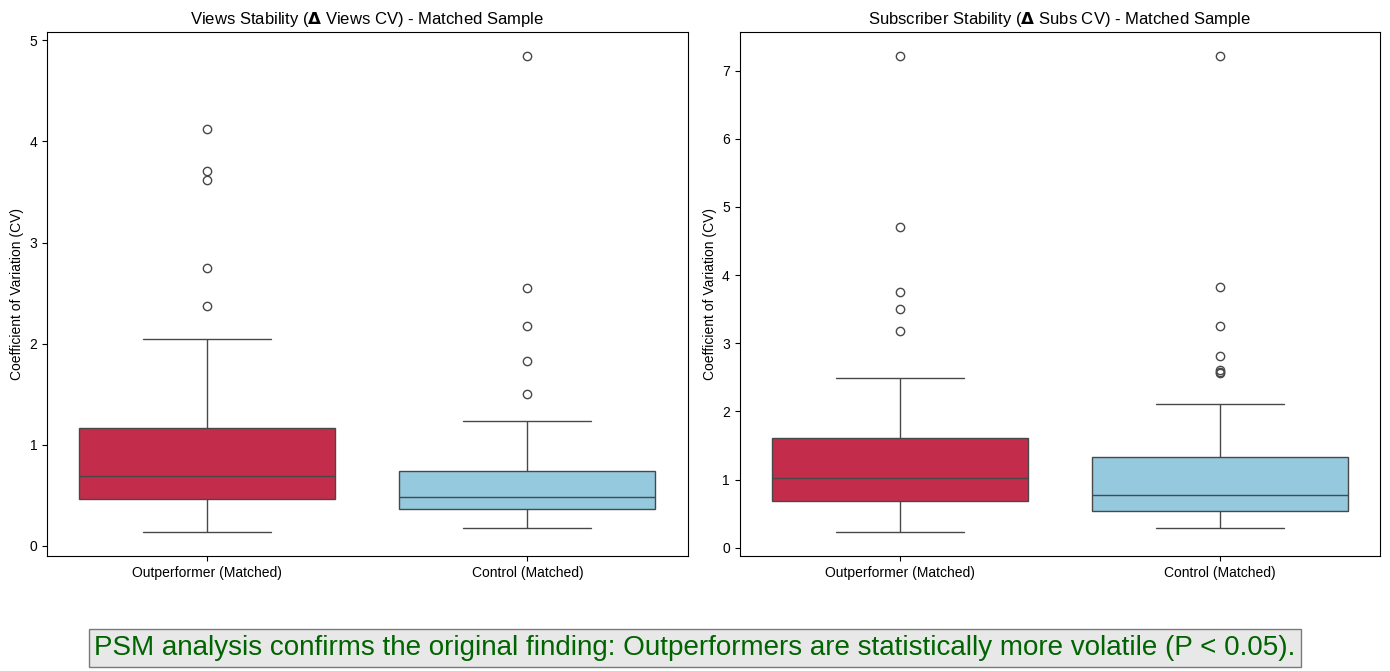

In [14]:
# ----------------------------------------------------------------------
# Visualize the difference in the *matched* groups
# ----------------------------------------------------------------------

# 0. Create copies for visualization
matched_outperformers_copy = matched_outperformers.copy()
matched_controls_copy = matched_controls.copy()

# 1. Add group labels
matched_outperformers_copy['Group'] = 'Outperformer (Matched)'
matched_controls_copy['Group'] = 'Control (Matched)'

# 2. Combine
df_cv_matched_plot = pd.concat([matched_outperformers_copy, matched_controls_copy], ignore_index=True)

# 3. Create Plots
print("\n--- Visualizing Matched CV Distribution ---")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plt.style.use('seaborn-v0_8-whitegrid')

# Views Stability
sns.boxplot(
    x='Group', y='cv_views', hue='Group', data=df_cv_matched_plot,
    ax=axes[0], palette=['crimson', 'skyblue'], legend=False
)
axes[0].set_title(r'Views Stability ($\mathbf{\Delta}$ Views CV) - Matched Sample')
axes[0].set_ylabel('Coefficient of Variation (CV)')
axes[0].set_xlabel('')

# Subscriber Stability
sns.boxplot(
    x='Group', y='cv_subs', hue='Group', data=df_cv_matched_plot,
    ax=axes[1], palette=['crimson', 'skyblue'], legend=False
)
axes[1].set_title(r'Subscriber Stability ($\mathbf{\Delta}$ Subs CV) - Matched Sample')
axes[1].set_ylabel('Coefficient of Variation (CV)')
axes[1].set_xlabel('')

fig.text(0.5, -0.1, 
         f"PSM analysis confirms the original finding: Outperformers are statistically more volatile (P < {THRESHOLD_ALPHA}).",
         ha='center', fontsize=20, color='darkgreen', bbox=dict(facecolor='lightgray', alpha=0.5))

plt.tight_layout()
plt.show()